# Trabalho Prático - Notebook do grupo

**Inteligência Artificial - Graduação** · Prof. Bruno Nogueira · FACOM/UFMS · 2026/2

**Grupo:** Chatbot MAIA · **Tema:** Esportes e Lazer na UFMS

---

Este é o notebook **entregável** do grupo. Ele precisa rodar do início ao fim
("Kernel → Restart & Run All") e **regerar os modelos** salvos em `modelos/`. A
estrutura segue o `00_exemplo_biblioteca.ipynb`; consulte-o sempre que tiver
dúvida.

Marcadores usados aqui:

* `🔨 TODO` - algo que o grupo precisa fazer/decidir;
* `📝 RELATÓRIO` - um resultado que deve aparecer (e ser discutido) no artigo.

Requisitos mínimos de cada seção estão no enunciado. Pode acrescentar seções,
células e análises à vontade - só não remova as seções numeradas.

---
## 0. Ambiente

In [1]:
import os
import subprocess
import sys
from pathlib import Path

# 🔨 TODO (só para o Colab): endereço do repositório do grupo
REPO_URL = "https://github.com/amanda-bea/IA-2026-02-TP-Chatbot"

if "google.colab" in sys.modules:
    pasta = Path("/content") / Path(REPO_URL).stem
    if not pasta.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(pasta)], check=True)
    os.chdir(pasta)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

raiz = Path.cwd()
while not (raiz / "chatbot").is_dir():
    if raiz.parent == raiz:
        raise RuntimeError("Rode este notebook de dentro do repositório do trabalho.")
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from chatbot.avaliacao import avaliar, tabela_resumo
from chatbot.config import carregar_config
from chatbot.dados import adicionar_escopo, carregar_dados, resumo, validar_dados, vazamento
from chatbot.grafo import Conversa, construir_grafo
from chatbot.modelos import carregar_classificadores, salvar_classificadores
from chatbot.representacoes import tfidf_caracteres, tfidf_palavras
from chatbot.rotulos import CLASSES_ESCOPO

# Imports adicionados pelo grupo
import re, unicodedata
from scipy import stats
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import roc_auc_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import learning_curve
from sklearn.linear_model import Perceptron
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier


warnings.filterwarnings("ignore")
RANDOM_STATE = 42
CORES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]
pd.set_option("display.max_colwidth", 80)

---
## 1. Configuração

🔨 TODO: preencha o `grupo.yaml` da raiz do repositório (tema e intenções
**validados com o professor**) antes de rodar esta seção.

In [3]:
config = carregar_config("grupo.yaml")
print("Grupo:", config.grupo, "| Tema:", config.tema)
pd.DataFrame([(i.nome, i.descricao) for i in config.intencoes.values()], columns=["intenção", "descrição"])

Grupo: MAIA | Tema: Esportes na UFMS


,intenção,descrição
0,modalidades_treinos,"modalidades oferecidas, turmas e horários de treino"
1,inscricao_programa,"como se inscrever nas turmas do Programa Universitário de Lazer, Saúde e Esp..."
2,atleticas,"atléticas, cadastro e fomento"
3,competicoes_jogos,"competições, jogos universitários e Copa Interatléticas"
4,apoio_atletas,apoio e bolsas para estudantes-atletas
5,espacos_esportivos,"locais de treino: quadras, complexo aquático e quadras de areia"
6,contato_proece,contato da Proece e dúvidas gerais sobre esportes


---
## 2. Dados

🔨 TODO: descreva aqui (em markdown) **como** os dados foram construídos: quem
escreveu, que fontes foram coletadas, que LLM e que *prompts* foram usados, como os
negativos difíceis foram pensados, como o teste foi obtido (ex.: formulário
respondido por N colegas).

📝 RELATÓRIO: tabela intenção × origem do treino e do teste.

In [4]:
treino = adicionar_escopo(carregar_dados(config.treino), config)
teste = adicionar_escopo(carregar_dados(config.teste), config)
print("Problemas no treino:", validar_dados(treino, config) or "nenhum")
print("Problemas no teste: ", validar_dados(teste, config) or "nenhum")
print("Vazamento treino→teste:", vazamento(treino, teste) or "nenhum")
display(resumo(treino))
display(resumo(teste))

Problemas no treino: nenhum
Problemas no teste:  nenhum
Vazamento treino→teste: nenhum


origem,llm,total
intencao,,
apoio_atletas,50,50
atleticas,50,50
chitchat,100,100
competicoes_jogos,47,47
contato_proece,50,50
espacos_esportivos,50,50
fora_dominio,100,100
inscricao_programa,48,48
modalidades_treinos,47,47


origem
intencao


### Gerando frases de treino com o LLM (opcional)

Rode no terminal (ou descomente a célula abaixo). As frases vão para
`dados/gerados_llm.csv` e os prompts ficam registrados em `dados/prompts_llm.md`.
**Revise tudo** antes de copiar para o `treino.csv`; nunca use no teste; declare no
`USO_DE_IA.md`.

In [ ]:
# Para rodar daqui, tire o "#" das linhas abaixo (gasta créditos da chave do grupo):
# subprocess.run([sys.executable, "scripts/gerar_dados_llm.py", "--n", "10"], check=True)
# gerados = pd.read_csv("dados/gerados_llm.csv")
# gerados.sample(15)

🔨 TODO: análise exploratória - tamanho das mensagens por classe, palavras mais
frequentes por intenção, exemplos de negativos difíceis, diferenças entre frases
humanas e de LLM...

1. TAMANHO DAS MENSAGENS POR CLASSE (treino)


,frases,média,mediana,mínimo,máximo
intencao,,,,,
modalidades_treinos,47,9.0,8.0,2,22
inscricao_programa,48,11.5,12.0,3,23
atleticas,50,10.4,9.0,3,25
competicoes_jogos,47,10.7,9.0,3,26
apoio_atletas,50,10.3,10.0,3,21
espacos_esportivos,50,9.9,10.0,3,21
contato_proece,50,12.4,12.0,3,27
chitchat,100,5.4,4.0,1,14
fora_dominio,100,9.9,9.0,2,24


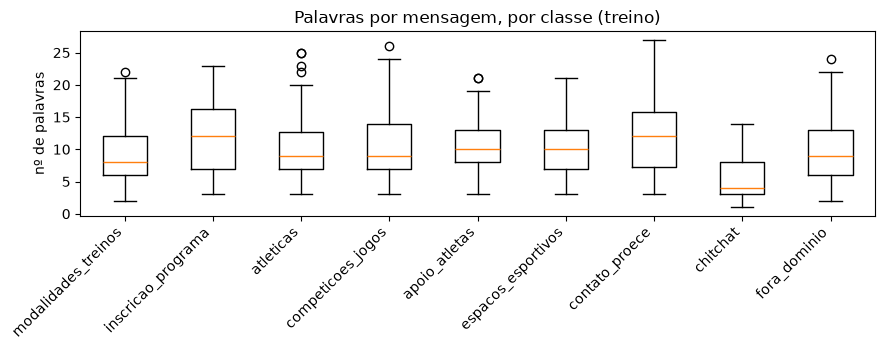


2. PALAVRAS MAIS FREQUENTES POR INTENÇÃO (treino)


,palavras mais frequentes
modalidades_treinos,"modalidades (12), turma (10), horarios (9), aulas (8), treino (7), turmas (6), volei (6), horario (6)"
inscricao_programa,"inscricao (24), programa (19), turmas (10), inscrever (8), universitario (8), lazer (8), saude (8), esporte (8)"
atleticas,"atletica (39), cadastro (12), fomento (12), ufms (9), cadastrar (7), precisa (7), documentos (6), atleticas (6)"
competicoes_jogos,"jogos (16), copa (14), universitarios (13), interatleticas (13), ano (6), vai (6), ufms (5), funciona (5)"
apoio_atletas,"atleta (34), bolsa (29), ufms (13), apoio (11), estudante (10), atletas (8), auxilio (8), financeiro (8)"
espacos_esportivos,"quadras (33), ficam (16), complexo (14), aquatico (14), campus (13), areia (13), ufms (9), perto (7)"
contato_proece,"proece (39), esporte (20), ufms (13), duvidas (9), atendimento (9), esportes (9), contato (7), esportivas (6)"
chitchat,"boa (10), bem (10), ate (10), estou (9), conversar (8), bom (7), pela (7), tudo (6)"
fora_dominio,"faco (14), sabe (8), posso (7), estou (7), cadastro (6), bolsa (6), onibus (6), preciso (6)"



3. NEGATIVOS DIFÍCEIS (treino)
% de negativos difíceis por classe:


,% difíceis
intencao,
chitchat,10.0
fora_dominio,57.0


Exemplos de negativos difíceis:


,texto,intencao,termos_do_dominio,origem
402,Oi! Estou correndo para terminar um trabalho e passei só para dar um alô.,chitchat,[estou],llm
403,Bom dia! Já acordei atrasada e estou tentando não entrar em pânico.,chitchat,[estou],llm
405,Obrigada mesmo! Estou com a cabeça cheia de provas hoje.,chitchat,[estou],llm
406,Até mais! Preciso correr para a aula antes que a porta feche.,chitchat,[preciso],llm
408,"Você é muito paciente comigo, ainda mais quando estou toda atrapalhada.",chitchat,"[ainda, estou]",llm
411,"Estou meio frustrada com a faculdade hoje, parece que tudo resolveu atrasar.",chitchat,[estou],llm
413,"Ainda estou me acostumando a conversar com um chatbot, mas achei bem tranquilo.",chitchat,"[ainda, estou]",llm
414,Fico pensando em como você consegue responder com tanta calma enquanto eu es...,chitchat,[estou],llm
419,"Certo, estou acompanhando, mesmo com mil coisas passando pela cabeça.",chitchat,[estou],llm
420,"Desculpa se escrevi tudo correndo, estou atrasada para entregar uma atividade.",chitchat,[estou],llm


... (2 outputs left out)

Frases por origem em cada classe (treino):


origem,llm
intencao,
modalidades_treinos,47
inscricao_programa,48
atleticas,50
competicoes_jogos,47
apoio_atletas,50
espacos_esportivos,50
contato_proece,50
chitchat,100
fora_dominio,100



Exemplos de origem 'llm':
  • Que bom encontrar você por aqui!
  • ainda da tempo de fazer minha inscrição no programa universitário
  • Deve ser interessante conversar com tantas pessoas diferentes, não acha?
  • Inscrição nas turmas
  • Inscrição no auxílio atleta
EXTRA A. QUASE-DUPLICATAS E RÓTULOS SUSPEITOS


ValueError: Found array with 0 sample(s) (shape=(0, 4709)) while a minimum of 1 is required by TfidfTransformer.

In [5]:
from collections import Counter

from chatbot.texto import normalizar

# ---------- preparação ----------
STOP = """a o as os um uma uns umas de do da dos das em no na nos nas por para pra com sem sobre
entre e ou mas que se como ao aos à às é são foi ser tem tenho têm ter há eu você voce vc tu ele ela
nós eles elas me te lhe meu minha seu sua isso isto esse essa este esta aqui ali lá la mais muito
já não nao sim só também qual quais quando onde quem quanto pq porque""".split()
STOP_N = {normalizar(w) for w in STOP}


def tokens(texto):
    return [t for t in normalizar(texto).split() if t not in STOP_N and len(t) > 1]


tr, te = treino.copy(), teste.copy()
for d in (tr, te):
    d["n_palavras"] = d["texto"].str.split().str.len()
    d["n_chars"] = d["texto"].str.len()
    d["eh_llm"] = d["origem"].eq("llm")

ORDEM = list(config.nomes_intencoes) + ["chitchat", "fora_dominio"]

# ============================================================
# 1. TAMANHO DAS MENSAGENS POR CLASSE
# ============================================================
print("1. TAMANHO DAS MENSAGENS POR CLASSE (treino)")
display(tr.groupby("intencao")["n_palavras"]
        .agg(frases="count", média="mean", mediana="median", mínimo="min", máximo="max")
        .reindex(ORDEM).round(1))

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.boxplot([tr.loc[tr["intencao"] == c, "n_palavras"] for c in ORDEM])
ax.set_xticklabels(ORDEM, rotation=45, ha="right")
ax.set_ylabel("nº de palavras")
ax.set_title("Palavras por mensagem, por classe (treino)")
plt.tight_layout()
plt.show()

# ============================================================
# 2. PALAVRAS MAIS FREQUENTES POR INTENÇÃO (sem stopwords)
# ============================================================
print("\n2. PALAVRAS MAIS FREQUENTES POR INTENÇÃO (treino)")
freq = {}
for c in ORDEM:
    cont = Counter(t for s in tr.loc[tr["intencao"] == c, "texto"] for t in tokens(s))
    freq[c] = ", ".join(f"{w} ({n})" for w, n in cont.most_common(8))
display(pd.DataFrame({"palavras mais frequentes": freq}).style.set_properties(**{"text-align": "left"}))

# ============================================================
# 3. NEGATIVOS DIFÍCEIS
#    = chitchat / fora_dominio que usam palavras típicas do domínio
# ============================================================
print("\n3. NEGATIVOS DIFÍCEIS (treino)")
cont_dom = Counter(t for s in tr.loc[tr["escopo"] == "dominio", "texto"] for t in tokens(s))
termos_dominio = {w for w, _ in cont_dom.most_common(40)}

neg = tr[tr["escopo"] != "dominio"].copy()
neg["termos_do_dominio"] = neg["texto"].apply(lambda s: sorted(set(tokens(s)) & termos_dominio))
neg["dificil"] = neg["termos_do_dominio"].str.len() > 0

print("% de negativos difíceis por classe:")
display((neg.groupby("intencao")["dificil"].mean() * 100).round(1).to_frame("% difíceis"))
print("Exemplos de negativos difíceis:")
display(neg[neg["dificil"]][["texto", "intencao", "termos_do_dominio", "origem"]].head(12))

# ============================================================
# 4. FRASES HUMANAS × FRASES DE LLM
# ============================================================
print("\n4. HUMANO × LLM (treino)")
t = tr["texto"].str.strip()
estilo = pd.DataFrame({
    "origem": tr["origem"],
    "palavras": tr["n_palavras"],
    "com acento": t.str.contains(r"[áàâãéêíóôõúç]", case=False),
    "termina com ?": t.str.endswith("?"),
    "tudo minúsculo": t == t.str.lower(),
    "tem pontuação final": t.str.contains(r"[.!?]$"),
})
tab_origem = estilo.groupby("origem").agg(
    frases=("palavras", "size"), palavras_média=("palavras", "mean"),
    com_acento=("com acento", "mean"), termina_com_interrogação=("termina com ?", "mean"),
    tudo_minúsculo=("tudo minúsculo", "mean"), pontuação_final=("tem pontuação final", "mean"))
display(tab_origem.round(2))

print("Frases por origem em cada classe (treino):")
display(pd.crosstab(tr["intencao"], tr["origem"]).reindex(ORDEM))

for o in tr["origem"].unique():
    print(f"\nExemplos de origem '{o}':")
    for s in tr.loc[tr["origem"] == o, "texto"].sample(min(5, (tr["origem"] == o).sum()), random_state=RANDOM_STATE):
        print("  •", s)

# ============================================================
# EXTRA A. QUALIDADE DOS DADOS: QUASE-DUPLICATAS E RÓTULOS SUSPEITOS
# (o teste entra só como diagnóstico; nenhuma escolha de modelo deve se basear nele)
# ============================================================

print("EXTRA A. QUASE-DUPLICATAS E RÓTULOS SUSPEITOS")
LIMIAR_SIM = 0.85   # heurística: acima disso, as frases são praticamente a mesma

d = tr.reset_index(drop=True)
t_ = te.reset_index(drop=True)
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), preprocessor=normalizar, sublinear_tf=True)
Xd = vec.fit_transform(d["texto"])
Xt = vec.transform(t_["texto"])

# ---- A1. Quase-duplicatas dentro do treino ----
# Se existem muitas, a validação cruzada "vê" a mesma frase no treino e na validação
# e fica otimista. É o problema típico de frases geradas em lote por LLM.
S = cosine_similarity(Xd)
np.fill_diagonal(S, 0)
viz = S.argmax(1)
sim_max = S.max(1)
print(f"\nA1. Treino com vizinho muito parecido (similaridade ≥ {LIMIAR_SIM}): {(sim_max >= LIMIAR_SIM).mean():.1%}")

pares = pd.DataFrame({"i": np.arange(len(d)), "j": viz, "sim": sim_max.round(2)})
pares["chave"] = pares.apply(lambda r: tuple(sorted((int(r.i), int(r.j)))), axis=1)
pares = pares.drop_duplicates("chave").query("sim >= @LIMIAR_SIM").sort_values("sim", ascending=False)
pares["frase A"] = d["texto"].iloc[pares["i"]].values
pares["frase B"] = d["texto"].iloc[pares["j"]].values
pares["classe A"] = d["intencao"].iloc[pares["i"]].values
pares["classe B"] = d["intencao"].iloc[pares["j"]].values
print("Pares mais parecidos (se as classes forem diferentes, é conflito de rótulo):")
display(pares[["frase A", "frase B", "classe A", "classe B", "sim"]].head(10))
print("Quase-duplicatas por classe (% das frases da classe com vizinho ≥ limiar):")
display(pd.Series(sim_max >= LIMIAR_SIM).groupby(d["intencao"]).mean().mul(100).round(1)
        .reindex(ORDEM).to_frame("% quase-duplicadas"))

# ---- A2. Teste muito parecido com o treino ----
# Teste quase igual ao treino mede memorização, não generalização.
S_te = cosine_similarity(Xt, Xd)
sim_te = S_te.max(1)
print(f"\nA2. Teste com vizinho ≥ {LIMIAR_SIM} no treino: {(sim_te >= LIMIAR_SIM).mean():.1%} "
      f"(mediana da similaridade: {np.median(sim_te):.2f})")
top_te = t_.assign(sim=sim_te.round(2), vizinho_no_treino=d["texto"].iloc[S_te.argmax(1)].values) \
           .sort_values("sim", ascending=False).head(8)
display(top_te[["texto", "vizinho_no_treino", "sim", "intencao"]])

# ---- A3. Rótulos suspeitos (confident learning simplificado) ----
# Para cada frase, a probabilidade que um modelo (sem ter visto a frase) dá ao rótulo
# anotado. Probabilidade muito baixa = rótulo errado, frase ambígua ou classe mal definida.
cv_a = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
pipe_a = Pipeline([("v", tfidf_caracteres()), ("c", LogisticRegression(C=10, max_iter=2000))])
P = cross_val_predict(pipe_a, d["texto"], d["intencao"], cv=cv_a, method="predict_proba")
classes_a = np.unique(d["intencao"])
p_rotulo = P[np.arange(len(d)), np.searchsorted(classes_a, d["intencao"])]
d["p_rotulo"] = p_rotulo.round(2)
d["previsto"] = classes_a[P.argmax(1)]

susp = d[(d["p_rotulo"] < 0.20) & (d["previsto"] != d["intencao"])].sort_values("p_rotulo")
print(f"\nA3. Frases com rótulo suspeito (p < 0.20 e previsão diferente): {len(susp)} ({len(susp) / len(d):.1%})")
display(susp[["texto", "intencao", "previsto", "p_rotulo", "origem"]].head(15))

print("Qual a classe mais 'confusa'? (probabilidade média no rótulo correto, por classe):")
display(d.groupby("intencao")["p_rotulo"].mean().round(2).sort_values().to_frame("p média no rótulo"))

print("Que pares de classes mais se confundem? (anotado → previsto, só erros):")
conf = pd.crosstab(d["intencao"], d["previsto"])
erros_par = conf.where(~np.eye(len(conf), dtype=bool)).stack().astype(int)
display(erros_par[erros_par > 0].sort_values(ascending=False).head(8).to_frame("nº de frases"))

# ============================================================
# EXTRA B. DUPLICATAS E RÓTULOS CONFLITANTES
# ============================================================
print("\nEXTRA B. DUPLICATAS NO TREINO")
tr["norm"] = tr["texto"].apply(normalizar)
n_dup = tr.duplicated("norm").sum()
conflitos = tr.groupby("norm")["intencao"].nunique()
conflitos = conflitos[conflitos > 1].index
print(f"Frases duplicadas (após normalizar): {n_dup} ({n_dup / len(tr):.1%})")
print(f"Frases com rótulos diferentes: {len(conflitos)}")
if len(conflitos):
    display(tr[tr["norm"].isin(conflitos)].sort_values("norm")[["texto", "intencao", "origem"]])

---
## 3. Representações de texto

🔨 TODO: escolha **pelo menos duas** representações para comparar. Os construtores
de `chatbot/representacoes.py` aceitam os parâmetros do `TfidfVectorizer`
(`ngram_range`, `min_df`, `stop_words`, ...). Embeddings pré-treinados
(`EmbeddingsSentenca`) são opcionais.

In [6]:
REPRESENTACOES = {
    "TF-IDF palavras (1-2)": tfidf_palavras,
    "TF-IDF caracteres (2-5)": tfidf_caracteres,
    "TF-IDF palavras (só unigramas)": lambda: tfidf_palavras(ngram_range=(1, 1)),
    "TF-IDF palavras (sem stopwords)": lambda: tfidf_palavras(stop_words=list(STOP_N)),
}

---
## 4. Classificador de escopo (dominio / chitchat / fora_dominio)

🔨 TODO: compare **pelo menos três algoritmos vistos em aula**, com validação
cruzada estratificada **só no treino**. Classificadores que ainda serão
apresentados na disciplina (KNN, Naive Bayes, SVM...) podem entrar quando forem
vistos.

📝 RELATÓRIO: tabela/gráfico da comparação, com média e desvio entre folds.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

CLASSIFICADORES = {
    "Regressão logística": lambda: LogisticRegression(C=10, max_iter=2000),
    "Rede neural (MLP)": lambda: MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, max_iter=600,
                                               random_state=RANDOM_STATE),
    "Árvore de decisão": lambda: DecisionTreeClassifier(random_state=RANDOM_STATE),
    "KNN (cosseno, k=5)": lambda: KNeighborsClassifier(n_neighbors=5, metric="cosine",
                                                       weights="distance", algorithm="brute"),
    "Perceptron": lambda: Perceptron(max_iter=1000, random_state=RANDOM_STATE),
    "Naive Bayes (multinomial)": lambda: MultinomialNB(alpha=0.1),
}

def comparar(textos, rotulos):
    linhas = []
    for nome_rep, rep in REPRESENTACOES.items():
        for nome_clf, clf in CLASSIFICADORES.items():
            pipe = Pipeline([("vetorizador", rep()), ("classificador", clf())])
            r = cross_validate(pipe, textos, rotulos, cv=cv, scoring=["f1_macro", "accuracy"],
                               return_train_score=True, n_jobs=-1)
            linhas.append({"representação": nome_rep, "classificador": nome_clf,
                           "F1 macro (CV)": r["test_f1_macro"].mean(), "desvio": r["test_f1_macro"].std(),
                           "acurácia (CV)": r["test_accuracy"].mean(),
                           "F1 macro (treino)": r["train_f1_macro"].mean()})
    return pd.DataFrame(linhas).sort_values("F1 macro (CV)", ascending=False).reset_index(drop=True)


tab_escopo = comparar(treino["texto"], treino["escopo"])
tab_escopo.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres (2-5),Perceptron,0.899,0.026,0.922,1.000
1,TF-IDF caracteres (2-5),Rede neural (MLP),0.892,0.016,0.915,1.000
2,TF-IDF palavras (só unigramas),Perceptron,0.885,0.013,0.911,1.000
3,TF-IDF palavras (só unigramas),Rede neural (MLP),0.884,0.027,0.911,1.000
4,TF-IDF palavras (só unigramas),Regressão logística,0.879,0.026,0.910,1.000
5,TF-IDF caracteres (2-5),Regressão logística,0.879,0.032,0.908,1.000
6,TF-IDF caracteres (2-5),Naive Bayes (multinomial),0.876,0.030,0.908,0.983
7,TF-IDF palavras (sem stopwords),Rede neural (MLP),0.875,0.028,0.911,1.000
8,TF-IDF palavras (1-2),Perceptron,0.871,0.027,0.902,1.000
9,TF-IDF palavras (sem stopwords),Perceptron,0.869,0.036,0.906,1.000


🔨 TODO: ajuste de hiperparâmetros dos melhores candidatos (`GridSearchCV`), curva
de validação e escolha justificada do modelo final de escopo.

In [ ]:
# 🔨 TODO: substitua pelo pipeline e pela grade escolhidos pelo grupo
busca_escopo = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=2000))]),
    param_grid={"classificador__C": [0.1, 1, 10, 100]},
    scoring="f1_macro", cv=cv, n_jobs=-1,
)
busca_escopo.fit(treino["texto"], treino["escopo"])
clf_escopo = busca_escopo.best_estimator_
print(busca_escopo.best_params_, round(busca_escopo.best_score_, 3))

📝 RELATÓRIO: matriz de confusão (validação cruzada), taxa de falso aceite e de
falsa recusa, e análise dos erros. Qual erro é mais grave **no seu domínio**?

In [ ]:
prev_cv = cross_val_predict(clf_escopo, treino["texto"], treino["escopo"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino["escopo"], prev_cv, labels=CLASSES_ESCOPO,
                                        cmap="Blues", colorbar=False)
plt.grid(False)
plt.show()
treino.assign(previsto=prev_cv).query("escopo != previsto")[["texto", "escopo", "previsto", "origem"]]

---
## 5. Classificador de tema (intenções do domínio)

🔨 TODO: mesma metodologia, treinando **só** com as mensagens do domínio.

In [ ]:
treino_dom = treino[treino["escopo"] == "dominio"]
tab_tema = comparar(treino_dom["texto"], treino_dom["intencao"])
tab_tema.round(3)

In [ ]:
# 🔨 TODO: ajuste de hiperparâmetros e escolha do modelo de tema
busca_tema = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=2000))]),
    param_grid={"classificador__C": [0.1, 1, 10, 100]},
    scoring="f1_macro", cv=cv, n_jobs=-1,
)
busca_tema.fit(treino_dom["texto"], treino_dom["intencao"])
clf_tema = busca_tema.best_estimator_
print(busca_tema.best_params_, round(busca_tema.best_score_, 3))

In [ ]:
prev_tema = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino_dom["intencao"], prev_tema, labels=config.nomes_intencoes,
                                        cmap="Blues", colorbar=False, xticks_rotation=45)
plt.grid(False)
plt.show()
print(classification_report(treino_dom["intencao"], prev_tema, zero_division=0))

---
## 6. Limiar de confiança

🔨 TODO: escolha `roteamento.limiar_tema` (no `grupo.yaml`) com base nas
probabilidades da validação cruzada, como na seção 9 do exemplo. Justifique.

In [ ]:
# 🔨 TODO

---
## 7. Salvar os modelos finais

In [ ]:
salvar_classificadores(clf_escopo, clf_tema, config)
config = carregar_config("grupo.yaml")  # relê, caso o limiar tenha sido alterado

---
## 8. O chatbot funcionando (com o LLM do OpenRouter)

🔨 TODO: reúna os documentos em `documentos/` (uma subpasta por intenção + `geral/`,
com o `FONTES.md`), ajuste `persona` e `contato` no `grupo.yaml` e mostre conversas
que ilustrem acertos **e** limitações do bot (inclusive perguntas cuja resposta
não está nos documentos). Se o grupo alterou o grafo (`chatbot/grafo.py`),
explique aqui o que mudou.

Antes: configure a chave no `.env` (ou nos *Secrets* do Colab) e rode
`python scripts/testar_llm.py`.

In [ ]:
from chatbot.conhecimento import BaseConhecimento
from chatbot.llm import ClienteLLM, ErroLLM, prompt_intencao

base = BaseConhecimento.carregar_ou_criar(config)   # cria o índice na 1ª vez
display(base.resumo())

# 🔨 TODO: teste a busca com perguntas do seu domínio (não gasta créditos)
pergunta, intencao = "TODO: uma pergunta do seu domínio", config.nomes_intencoes[0]
for tr, sim in base.buscar(pergunta, intencao=intencao):
    print(f"{sim:.2f}  {tr.fonte} | {tr.texto[:80]!r}")

In [ ]:
# o prompt que o LLM recebe para essa pergunta
for m in prompt_intencao(config, intencao, pergunta, trechos=base.buscar(pergunta, intencao=intencao)):
    print(f"--- {m['role']} ---\n{m['content']}\n")

In [ ]:
try:
    llm = ClienteLLM.da_config(config)
except ErroLLM as erro:
    print("Sem LLM:", erro)
    llm = None

conversa = Conversa(config, clf_escopo, clf_tema, llm=llm, base=base)
for m in ["oi!", "TODO: escreva mensagens do seu domínio", "obrigado"]:
    e = conversa.enviar(m)
    print(f"você: {m}\n  [rota={e['rota']} | resposta {e['fonte_resposta']}]\n  bot: {e['resposta']}\n")
if llm:
    print("Uso do LLM:", llm.uso)

---
## 9. Avaliação final no teste (uma única vez)

📝 RELATÓRIO: tabela dos três níveis, matriz de confusão ponta a ponta e análise
dos erros (separando, se possível, por origem das frases).

In [ ]:
clf_escopo, clf_tema = carregar_classificadores(config)
grafo = construir_grafo(config, clf_escopo, clf_tema)
resultado, previsoes = avaliar(config, clf_escopo, clf_tema, grafo, teste)
tab, extras = tabela_resumo(resultado)
display(tab.round(3))
display(extras.round(3))
previsoes.loc[~previsoes["acertou"], ["texto", "real", "rota", "confianca_escopo", "confianca_intencao"]]

---
## 10. Uso de IA generativa

🔨 TODO: confira se **todo** uso de IA do grupo (geração de dados, LLM do bot,
código, escrita, ideias, depuração...) está no `USO_DE_IA.md` e será copiado para a
seção própria do artigo e mencionado no vídeo. **Uso não declarado = nota zero
(plágio).**

---
## 11. Verificação da entrega

Deve terminar com **0 erro(s)**.

In [ ]:
!{sys.executable} scripts/verificar_entrega.py